Level 1: Two Traders, Two Strategies

Axes of Variation

1. **Number of traders:** 2.
2. **Strategy switching:** Deterministic weekly switching. Each trader selects the strategy with the higher return over the previous calendar week's trading days.
3. **Number of strategies:** 2. One-day momentum and one-day contrarian.
4. **Firm policy:** Evaluate returns only. No quorum, capital reallocation, hiring, or firing.
5. **Market history:** Fixed historical SPY data from 2024.
6. **Added market shocks:** None. The historical price fluctuations remain unchanged.
7. **Strategy lookback:** Both trading strategies use the closing-price change between the two previous trading days. Strategy selection uses the previous week's strategy returns.
8. **Market-price independence:** The firm's trades do not affect market prices.

Trading Strategy - One-Day Momentum

1. **Basic idea:** The trader follows the direction of the previous trading day's closing-price change.
2. **Positive price change:** If the previous close was higher than the close before it, buy using all available cash or hold if already invested.
3. **Negative price change:** If the previous close was lower than the close before it, sell all owned shares or remain in cash.
4. **No price change:** If the two closes were equal, keep the current position.
5. **Execution timing:** Use the two most recent completed closing prices to decide what to do at the next trading day's open. Execute trades at that opening price.
6. **Information restriction:** Today's closing price cannot influence today's opening trade.
7. **Holding period:** Positions remain in place, including overnight, until a later trading decision changes them.

Trading Strategy - One-Day Contrarian

1. **Basic idea:** The trader acts against the direction of the previous trading day's closing-price change.
2. **Positive price change:** If the previous close was higher than the close before it, sell all owned shares or remain in cash.
3. **Negative price change:** If the previous close was lower than the close before it, buy using all available cash or hold if already invested.
4. **No price change:** If the two closes were equal, keep the current position.
5. **Execution timing:** Use the two most recent completed closing prices to decide what to do at the next trading day's open. Execute trades at that opening price.
6. **Information restriction:** Today's closing price cannot influence today's opening trade.
7. **Holding period:** Positions remain in place, including overnight, until a later trading decision changes them.

Strategy Evaluation and Switching

1. **Starting strategies:** Trader 1 starts with momentum. Trader 2 starts with contrarian.
2. **Review timing:** Review before the first trading day's open in each new calendar week. If Monday is a holiday, review on the next available trading day.
3. **Review period:** Compare strategy returns over the previous calendar week's available trading days.
4. **Strategy tracking:** Evaluate both strategies throughout each week, even when neither trader is using one of them.
5. **Equal starting conditions:** Each strategy's hypothetical evaluation account starts each week with $5,000 in cash and zero shares.
6. **Strategy return:** Calculate each hypothetical account's percentage return from its starting cash to its value at the week's final close. These accounts measure strategy performance and add no money to the firm.
7. **Selection rule:** Both traders select the strategy with the higher weekly percentage return. If both strategies lose money, select the one with the smaller loss.
8. **Tie rule:** If the strategy returns are equal, each trader keeps their current strategy.
9. **Switching behavior:** Both traders decide simultaneously. Their selected strategies determine their actions at that day's open.
10. **Portfolio continuity:** Switching does not reset a trader's cash or shares and does not automatically force a sale.
11. **First review:** Keep the assigned starting strategies during the first evaluation week. Review that week's performance at the start of the following week.
12. **Holiday handling:** Detect a new calendar week by comparing the current trading date with the previous trading date. A shortened week uses only its available trading days.

Portfolio and Firm Rules

1. **Starting capital:** The firm begins with $10,000, divided equally between its two traders.
2. **Starting position:** Each trader begins with $5,000 in cash and zero shares.
3. **Capital allocation:** Traders keep separate portfolios. No money is transferred between them or rebalanced at weekly reviews.
4. **Position size:** Purchases use all available cash. Sales liquidate the entire position. Fractional shares are allowed.
5. **Allowed actions:** Buy, sell, or hold. Traders can sell only shares they already own.
6. **Restrictions:** No short selling, borrowing, or leverage.
7. **Costs and income:** Transaction costs, slippage, dividends, and cash interest are excluded.
8. **Price data:** Use SPY opening and closing prices without dividend adjustments.
9. **Firm behavior:** The firm observes and evaluates trader performance without influencing trading decisions.
10. **Final position:** Remaining shares are valued at the final 2024 closing price without forcing a sale.

Performance Evaluation

1. **Trader portfolio value:** At each trading day's close, add the trader's cash to the closing market value of their shares.

   $$
   V_i(t) = C_i(t) + Q_i(t)P(t)
   $$

   - $V_i(t)$: Trader $i$'s portfolio value at time $t$
   - $C_i(t)$: Trader $i$'s cash at time $t$
   - $Q_i(t)$: Trader $i$'s shares at time $t$
   - $P(t)$: SPY's closing price at time $t$

2. **Trader cumulative return:** Divide the gain or loss by the trader's initial capital, then multiply by 100.

   $$
   R_i(t) =
   \frac{V_i(t) - V_i(0)}{V_i(0)}
   \times 100
   $$

   For this model, $V_i(0) = 5{,}000$ for each trader.

3. **Firm portfolio value:** Add the portfolio values of both traders.

   $$
   V_{\text{firm}}(t) = \sum_{i=1}^{2} V_i(t)
   $$

   Trader portfolios may have different values even when both traders use the same strategy.

4. **Firm cumulative return:** Divide the firm's total gain or loss by its initial $10,000, then multiply by 100.

   $$
   R_{\text{firm}}(t) =
   \frac{V_{\text{firm}}(t) - 10{,}000}{10{,}000}
   \times 100
   $$

In [1]:
%pip install yfinance pandas matplotlib


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
from importlib.metadata import version

import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from IPython.display import display

STARTING_CASH = 10_000.0
START_DATE = "2024-01-01"
END_DATE = "2024-12-31"

data_folder = Path("data")
data_folder.mkdir(exist_ok=True)
data_file = data_folder / "spy_2024_with_warmup.csv"

# Reuse our saved prices so repeated runs use the same data
if data_file.exists():
    prices = pd.read_csv(data_file, index_col="Date", parse_dates=True)

else:
    prices = yf.download(
        "SPY",
        start="2023-12-28",  # Include two earlier closes for our first signal
        end="2025-01-01",  # The download excludes this end date
        auto_adjust=False,
        multi_level_index=False,
        progress=False,
    )

    if prices is None or prices.empty:
        raise ValueError("No prices downloaded. Check your connection and retry.")

    prices = prices[["Open", "Close"]].copy()
    prices.index.name = "Date"

    # Save the prices and use that saved copy on this run too
    prices.to_csv(data_file)
    prices = pd.read_csv(data_file, index_col="Date", parse_dates=True)

    # Record package versions so we can recreate our setup
    packages = ["yfinance", "pandas", "matplotlib"]
    versions = "\n".join(f"{name}=={version(name)}" for name in packages)
    (data_folder / "package_versions.txt").write_text(versions)

display(prices.head())

,Open,Close
Date,,
2023-12-28,476.880005,476.690002
2023-12-29,476.489990,475.309998
2024-01-02,472.160004,472.649994
2024-01-03,470.429993,468.790009
2024-01-04,468.299988,467.279999


Simulation

In [3]:
def execute_trade(cash, shares, signal, opening_price):
    # Buy using only our available cash
    if signal > 0 and cash > 0:
        return 0.0, cash / opening_price, "BUY"

    # Sell only the shares we already own
    if signal < 0 and shares > 0:
        return shares * opening_price, 0.0, "SELL"

    return cash, shares, "HOLD"


def run_model(prices, starting_cash, start, end):
    if starting_cash <= 0:
        raise ValueError("Starting cash must be positive")

    # Check that our dates are unique and in chronological order
    if (
        prices.empty
        or not prices.index.is_unique
        or not prices.index.is_monotonic_increasing
    ):
        raise ValueError("Data must have unique dates in order")

    # Stop if opening or closing prices are missing or nonpositive
    if (
        prices[["Open", "Close"]].isna().any().any()
        or (prices[["Open", "Close"]] <= 0).any().any()
    ):
        raise ValueError("Opening and closing prices must be present and positive")

    # Use only the two closes known before each day's open
    changes = prices["Close"].shift(1) - prices["Close"].shift(2)
    days = prices.loc[start:end]

    if days.empty or changes.loc[days.index].isna().any():
        raise ValueError("We need evaluation data and two earlier closes")

    allocation = starting_cash / 2

    # Each trader keeps their own money and holdings throughout the simulation
    traders = [
        {
            "Trader": "Trader 1",
            "Strategy": "Momentum",
            "Cash": allocation,
            "Shares": 0.0,
        },
        {
            "Trader": "Trader 2",
            "Strategy": "Contrarian",
            "Cash": allocation,
            "Shares": 0.0,
        },
    ]

    records = []
    reviews = []
    current_week = None

    for date, day in days.iterrows():
        # Each period runs Monday through Sunday, including across year boundaries
        week = date.to_period("W-SUN")

        if week != current_week:
            # Skip the first review so traders begin with their assigned strategies
            if current_week is not None:
                strategy_returns = {
                    name: 100 * (account["Value"] - allocation) / allocation
                    for name, account in scores.items()
                }

                momentum_return = strategy_returns["Momentum"]
                contrarian_return = strategy_returns["Contrarian"]

                if momentum_return > contrarian_return:
                    winner = "Momentum"
                elif contrarian_return > momentum_return:
                    winner = "Contrarian"
                else:
                    winner = "Tie"

                # Both traders use the same completed-week scores before trading
                for trader in traders:
                    if winner != "Tie":
                        trader["Strategy"] = winner

                reviews.append({
                    "ReviewDate": date,
                    "PeriodStart": week_start,
                    "PeriodEnd": previous_date,
                    "MomentumReturnPct": momentum_return,
                    "ContrarianReturnPct": contrarian_return,
                    "Winner": winner,
                    "Trader1Strategy": traders[0]["Strategy"],
                    "Trader2Strategy": traders[1]["Strategy"],
                })

            # Reset only the hypothetical scoring accounts for the new week
            scores = {
                name: {"Cash": allocation, "Shares": 0.0}
                for name in ["Momentum", "Contrarian"]
            }

            current_week = week
            week_start = date

        change = changes.loc[date]
        momentum_signal = 1 if change > 0 else -1 if change < 0 else 0

        # Contrarian uses the opposite signal, while zero means hold for both
        signals = {
            "Momentum": momentum_signal,
            "Contrarian": -momentum_signal,
        }

        # Trade each actual portfolio using its selected strategy
        for trader in traders:
            signal = signals[trader["Strategy"]]

            trader["Cash"], trader["Shares"], trader["Action"] = execute_trade(
                trader["Cash"],
                trader["Shares"],
                signal,
                day["Open"],
            )

            trader["Value"] = (
                trader["Cash"] + trader["Shares"] * day["Close"]
            )

        firm_value = sum(trader["Value"] for trader in traders)

        # Save one row per trader per date
        for trader in traders:
            records.append({
                "Date": date,
                "Trader": trader["Trader"],
                "Strategy": trader["Strategy"],
                "Open": day["Open"],
                "Close": day["Close"],
                "Signal": signals[trader["Strategy"]],
                "Action": trader["Action"],
                "Cash": trader["Cash"],
                "Shares": trader["Shares"],
                "TraderValue": trader["Value"],
                "TraderReturnPct": (
                    100 * (trader["Value"] - allocation) / allocation
                ),
                "FirmValue": firm_value,
                "FirmReturnPct": (
                    100 * (firm_value - starting_cash) / starting_cash
                ),
            })

        # Track both strategies even when no actual trader is using one
        for name, account in scores.items():
            account["Cash"], account["Shares"], _ = execute_trade(
                account["Cash"],
                account["Shares"],
                signals[name],
                day["Open"],
            )

            # Save today's closing value for the next weekly review
            account["Value"] = (
                account["Cash"] + account["Shares"] * day["Close"]
            )

        previous_date = date

    return pd.DataFrame(records), pd.DataFrame(reviews)

In [4]:
# Use made-up prices so we can check the results by hand
example = pd.DataFrame({
    "Open": [
        100, 100, 100, 111, 120, 105,
        102, 100, 125, 110, 110, 100,
    ],
    "Close": [
        100, 102, 110, 105, 100, 100,
        110, 120, 115, 110, 110, 105,
    ],
})

example.index = pd.to_datetime([
    "2023-12-28", "2023-12-29",
    "2024-01-02", "2024-01-03", "2024-01-04", "2024-01-05",
    "2024-01-08", "2024-01-09", "2024-01-10", "2024-01-11",
    "2024-01-12", "2024-01-16",
])

check, check_reviews = run_model(
    example, STARTING_CASH, START_DATE, END_DATE
)

# Check that reviews happen on the first trading day of each new week
expected_reviews = pd.to_datetime(["2024-01-08", "2024-01-16"])
assert check_reviews["ReviewDate"].tolist() == expected_reviews.tolist()
assert check_reviews["Winner"].tolist() == ["Momentum", "Momentum"]

# Check the first week's strategy returns against our hand calculations
assert round(check_reviews.iloc[0]["MomentumReturnPct"], 6) == 20.0
assert round(check_reviews.iloc[0]["ContrarianReturnPct"], 6) == -16.666667

trader_1_check = check[check["Trader"] == "Trader 1"]

expected_actions = [
    "BUY", "HOLD", "SELL", "HOLD", "HOLD",
    "BUY", "HOLD", "SELL", "HOLD", "HOLD",
]

expected_values = [
    5500, 5250, 6000, 6000, 6000,
    7200, 6900, 6600, 6600, 6600,
]

assert trader_1_check["Action"].tolist() == expected_actions
assert trader_1_check["TraderValue"].round(2).tolist() == expected_values

# Firm value must equal the sum of the two actual portfolios
trader_totals = check.groupby("Date")["TraderValue"].sum()
firm_totals = check.groupby("Date")["FirmValue"].first()
assert (trader_totals - firm_totals).abs().max() < 0.000001

# Changing the review day's close cannot affect that morning's decision
changed_example = example.copy()
changed_example.loc["2024-01-08", "Close"] = 50

changed_check, changed_reviews = run_model(
    changed_example, STARTING_CASH, START_DATE, END_DATE
)

assert check_reviews.iloc[0].equals(changed_reviews.iloc[0])

review_day = check[check["Date"] == "2024-01-08"]
changed_review_day = changed_check[changed_check["Date"] == "2024-01-08"]

assert review_day["Shares"].tolist() == changed_review_day["Shares"].tolist()

# Equal strategy returns leave each trader on their current strategy
flat_example = example.copy()
flat_example["Open"] = 100
flat_example["Close"] = 100

flat_check, flat_reviews = run_model(
    flat_example, STARTING_CASH, START_DATE, END_DATE
)

assert flat_reviews["Winner"].eq("Tie").all()
assert flat_check.loc[
    flat_check["Trader"] == "Trader 1", "Strategy"
].eq("Momentum").all()
assert flat_check.loc[
    flat_check["Trader"] == "Trader 2", "Strategy"
].eq("Contrarian").all()

# An unused strategy can win and attract both traders at the next review
unused_example = example.copy()
unused_example.loc["2024-01-11", "Open"] = 80

unused_check, unused_reviews = run_model(
    unused_example, STARTING_CASH, START_DATE, END_DATE
)

assert unused_reviews["Winner"].tolist() == ["Momentum", "Contrarian"]
assert unused_check.loc[
    unused_check["Date"] == "2024-01-16", "Strategy"
].eq("Contrarian").all()

print("All checks passed")

display(check_reviews.round(4))
display(check[[
    "Date", "Trader", "Strategy", "Signal",
    "Action", "Cash", "Shares", "TraderValue",
]].round(4))

All checks passed


,ReviewDate,PeriodStart,PeriodEnd,MomentumReturnPct,ContrarianReturnPct,Winner,Trader1Strategy,Trader2Strategy
0,2024-01-08,2024-01-02,2024-01-05,20.0,-16.6667,Momentum,Momentum,Momentum
1,2024-01-16,2024-01-08,2024-01-12,10.0,0.0000,Momentum,Momentum,Momentum


,Date,Trader,Strategy,Signal,Action,Cash,Shares,TraderValue
0,2024-01-02,Trader 1,Momentum,1,BUY,0.0000,50.0000,5500.0000
1,2024-01-02,Trader 2,Contrarian,-1,HOLD,5000.0000,0.0000,5000.0000
2,2024-01-03,Trader 1,Momentum,1,HOLD,0.0000,50.0000,5250.0000
3,2024-01-03,Trader 2,Contrarian,-1,HOLD,5000.0000,0.0000,5000.0000
4,2024-01-04,Trader 1,Momentum,-1,SELL,6000.0000,0.0000,6000.0000
5,2024-01-04,Trader 2,Contrarian,1,BUY,0.0000,41.6667,4166.6667
6,2024-01-05,Trader 1,Momentum,-1,HOLD,6000.0000,0.0000,6000.0000
7,2024-01-05,Trader 2,Contrarian,1,HOLD,0.0000,41.6667,4166.6667
8,2024-01-08,Trader 1,Momentum,0,HOLD,6000.0000,0.0000,6000.0000
9,2024-01-08,Trader 2,Momentum,0,HOLD,0.0000,41.6667,4583.3333


In [5]:
results, reviews = run_model(
    prices, STARTING_CASH, START_DATE, END_DATE
)

# Keep one firm observation per date instead of counting it twice
firm_daily = results.drop_duplicates("Date").set_index("Date")

final_traders = (
    results.groupby("Trader", sort=False)
    .tail(1)
    .set_index("Trader")
)

summary = final_traders[["TraderValue", "TraderReturnPct"]].rename(
    columns={
        "TraderValue": "Final value ($)",
        "TraderReturnPct": "Cumulative return (%)",
    }
)

summary.loc["Firm"] = [
    firm_daily["FirmValue"].iloc[-1],
    firm_daily["FirmReturnPct"].iloc[-1],
]

display(summary.round(2))

for trader in ["Trader 1", "Trader 2"]:
    trader_results = results[results["Trader"] == trader]
    print(
        trader,
        "| Purchases:", int(trader_results["Action"].eq("BUY").sum()),
        "| Sales:", int(trader_results["Action"].eq("SELL").sum()),
    )

# Show both traders for the first ten trading days
first_dates = results["Date"].drop_duplicates().head(10)
display(results[results["Date"].isin(first_dates)].round(4))

# Show the weekly scores and strategy choices
display(reviews.round(4))

results.to_csv(data_folder / "level_1_daily_results.csv", index=False)
reviews.to_csv(data_folder / "level_1_weekly_reviews.csv", index=False)

,Final value ($),Cumulative return (%)
Trader,,
Trader 1,5381.99,7.64
Trader 2,5339.48,6.79
Firm,10721.47,7.21


Trader 1 | Purchases: 58 | Sales: 58
Trader 2 | Purchases: 58 | Sales: 58


,Date,Trader,Strategy,Open,Close,Signal,Action,Cash,Shares,TraderValue,TraderReturnPct,FirmValue,FirmReturnPct
0,2024-01-02,Trader 1,Momentum,472.16,472.65,-1,HOLD,5000.0000,0.0000,5000.0000,0.0000,10005.1888,0.0519
1,2024-01-02,Trader 2,Contrarian,472.16,472.65,1,BUY,0.0000,10.5896,5005.1888,0.1038,10005.1888,0.0519
2,2024-01-03,Trader 1,Momentum,470.43,468.79,-1,HOLD,5000.0000,0.0000,5000.0000,0.0000,9964.3130,-0.3569
3,2024-01-03,Trader 2,Contrarian,470.43,468.79,1,HOLD,0.0000,10.5896,4964.3130,-0.7137,9964.3130,-0.3569
4,2024-01-04,Trader 1,Momentum,468.30,467.28,-1,HOLD,5000.0000,0.0000,5000.0000,0.0000,9948.3226,-0.5168
5,2024-01-04,Trader 2,Contrarian,468.30,467.28,1,HOLD,0.0000,10.5896,4948.3226,-1.0335,9948.3226,-0.5168
6,2024-01-05,Trader 1,Momentum,467.49,467.92,-1,HOLD,5000.0000,0.0000,5000.0000,0.0000,9955.1001,-0.4490
7,2024-01-05,Trader 2,Contrarian,467.49,467.92,1,HOLD,0.0000,10.5896,4955.1001,-0.8980,9955.1001,-0.4490
8,2024-01-08,Trader 1,Momentum,468.43,474.60,1,BUY,0.0000,10.6740,5065.8584,1.3172,10091.6972,0.9170
9,2024-01-08,Trader 2,Momentum,468.43,474.60,1,HOLD,0.0000,10.5896,5025.8387,0.5168,10091.6972,0.9170


,ReviewDate,PeriodStart,PeriodEnd,MomentumReturnPct,ContrarianReturnPct,Winner,Trader1Strategy,Trader2Strategy
0,2024-01-08,2024-01-02,2024-01-05,0.0000,-0.8980,Momentum,Momentum,Momentum
1,2024-01-16,2024-01-08,2024-01-12,1.2762,0.4789,Momentum,Momentum,Momentum
2,2024-01-22,2024-01-16,2024-01-19,0.2697,1.2356,Contrarian,Contrarian,Contrarian
3,2024-01-29,2024-01-22,2024-01-26,0.7025,0.0000,Momentum,Momentum,Momentum
4,2024-02-05,2024-01-29,2024-02-02,0.5606,0.7923,Contrarian,Contrarian,Contrarian
5,2024-02-12,2024-02-05,2024-02-09,0.9525,0.5613,Momentum,Momentum,Momentum
6,2024-02-20,2024-02-12,2024-02-16,-1.2814,0.9625,Contrarian,Contrarian,Contrarian
7,2024-02-26,2024-02-20,2024-02-23,0.7619,1.2638,Contrarian,Contrarian,Contrarian
8,2024-03-04,2024-02-26,2024-03-01,0.9878,-0.0918,Momentum,Momentum,Momentum
9,2024-03-11,2024-03-04,2024-03-08,-0.6254,0.5684,Contrarian,Contrarian,Contrarian


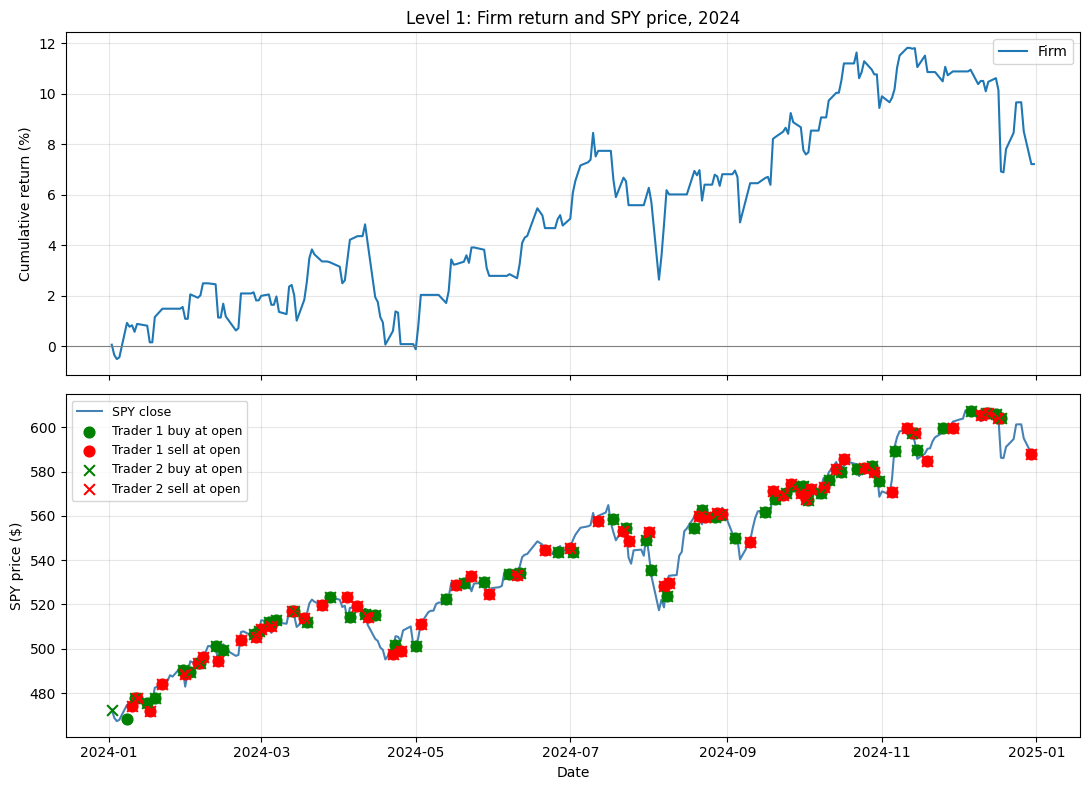

In [6]:
fig, (return_ax, price_ax) = plt.subplots(
    2, 1, figsize=(11, 8), sharex=True
)

return_ax.plot(
    firm_daily.index,
    firm_daily["FirmReturnPct"],
    label="Firm",
)

return_ax.axhline(0, color="gray", linewidth=0.8)
return_ax.set_title("Level 1: Firm return and SPY price, 2024")
return_ax.set_ylabel("Cumulative return (%)")
return_ax.legend()
return_ax.grid(alpha=0.3)

price_ax.plot(
    firm_daily.index,
    firm_daily["Close"],
    label="SPY close",
    color="steelblue",
)

# Marks show opening execution prices while the line shows closing prices
for trader, marker in [("Trader 1", "o"), ("Trader 2", "x")]:
    for action, color in [("BUY", "green"), ("SELL", "red")]:
        trades = results[
            (results["Trader"] == trader)
            & (results["Action"] == action)
        ]

        price_ax.scatter(
            trades["Date"],
            trades["Open"],
            color=color,
            marker=marker,
            s=60,
            label=f"{trader} {action.lower()} at open",
            zorder=3,
        )

price_ax.set_xlabel("Date")
price_ax.set_ylabel("SPY price ($)")
price_ax.legend(fontsize=9)
price_ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

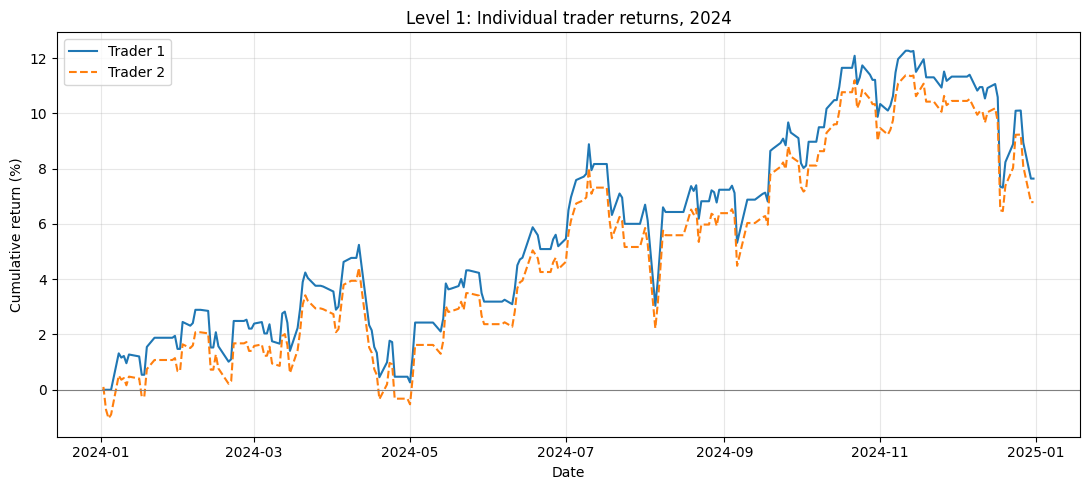

In [7]:
fig, ax = plt.subplots(figsize=(11, 5))

for trader, style in [("Trader 1", "-"), ("Trader 2", "--")]:
    trader_results = results[results["Trader"] == trader]

    ax.plot(
        trader_results["Date"],
        trader_results["TraderReturnPct"],
        linestyle=style,
        label=trader,
    )

ax.axhline(0, color="gray", linewidth=0.8)
ax.set_title("Level 1: Individual trader returns, 2024")
ax.set_xlabel("Date")
ax.set_ylabel("Cumulative return (%)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [8]:
# Collect the actual trader and firm portfolio values
values = results.pivot(
    index="Date", columns="Trader", values="TraderValue"
)

values["Firm"] = results.groupby("Date")["FirmValue"].first()

days = prices.loc[values.index]
changes = prices["Close"].shift(1) - prices["Close"].shift(2)


def fixed_strategy_values(direction):
    # Follow one strategy throughout the year without weekly resets or switching
    cash = STARTING_CASH / 2
    shares = 0.0
    daily_values = []

    for date, day in days.iterrows():
        change = changes.loc[date]
        signal = 1 if change > 0 else -1 if change < 0 else 0

        cash, shares, _ = execute_trade(
            cash, shares, direction * signal, day["Open"]
        )

        daily_values.append(cash + shares * day["Close"])

    return daily_values


values["Strategy 1: Momentum"] = fixed_strategy_values(1)
values["Strategy 2: Contrarian"] = fixed_strategy_values(-1)

values = values[[
    "Firm",
    "Trader 1",
    "Trader 2",
    "Strategy 1: Momentum",
    "Strategy 2: Contrarian",
]]

starting_values = pd.Series({
    "Firm": STARTING_CASH,
    "Trader 1": STARTING_CASH / 2,
    "Trader 2": STARTING_CASH / 2,
    "Strategy 1: Momentum": STARTING_CASH / 2,
    "Strategy 2: Contrarian": STARTING_CASH / 2,
})

# Compare each month-end value with the previous month-end value
month_end = values.groupby(values.index.to_period("M")).last()
month_start = month_end.shift(1)
month_start.iloc[0] = starting_values

monthly_returns = 100 * (month_end / month_start - 1)
monthly_returns.index = monthly_returns.index.astype(str)

# Overall return uses the original starting capital
overall = 100 * (values.iloc[-1] / starting_values - 1)

return_table = pd.concat([
    overall.to_frame().T.rename(index={0: "Overall"}),
    monthly_returns,
])

return_table.index.name = "Period"

display(return_table.style.format("{:.2f}%"))

Trader,Firm,Trader 1,Trader 2,Strategy 1: Momentum,Strategy 2: Contrarian
Period,,,,,
Overall,7.21%,7.64%,6.79%,12.06%,10.77%
2024-01,1.08%,1.48%,0.68%,2.26%,0.01%
2024-02,0.72%,0.72%,0.72%,1.20%,3.97%
2024-03,1.49%,1.49%,1.49%,1.16%,1.77%
2024-04,-3.15%,-3.15%,-3.15%,-4.16%,0.13%
2024-05,2.70%,2.70%,2.70%,2.86%,2.13%
2024-06,1.94%,1.94%,1.94%,2.93%,0.26%
2024-07,1.11%,1.11%,1.11%,1.69%,-0.47%
2024-08,0.83%,0.83%,0.83%,0.71%,1.62%


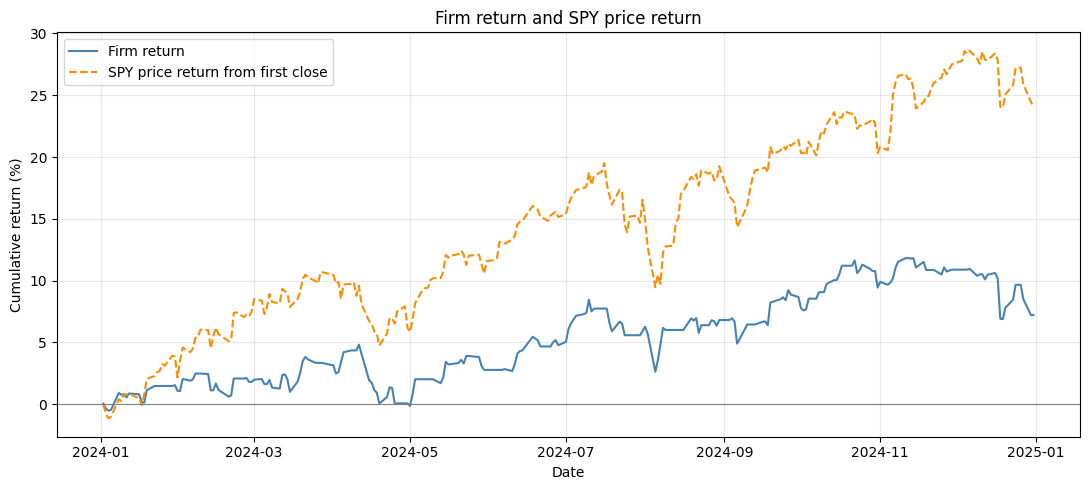

In [10]:
daily = results.copy()

if "Date" not in daily.columns:
    daily = daily.reset_index()

# Keep one firm observation per date
daily = daily.drop_duplicates("Date").sort_values("Date")

# Measure SPY's percentage change from the first closing price
spy_return = 100 * (daily["Close"] / daily["Close"].iloc[0] - 1)

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    daily["Date"],
    daily["FirmReturnPct"],
    label="Firm return",
    color="steelblue",
)

ax.plot(
    daily["Date"],
    spy_return,
    label="SPY price return from first close",
    color="darkorange",
    linestyle="--",
)

ax.axhline(0, color="gray", linewidth=0.8)
ax.set_title("Firm return and SPY price return")
ax.set_xlabel("Date")
ax.set_ylabel("Cumulative return (%)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()